# Introduction to Python Project : FoodHub Data Analysis

### Problem Statement

A food aggreator **FoodHub** company want to identify the demand of different restaurants so that it can improve its business and customer experience   


### Data Dictionary
* order_id: Unique ID of the order
* customer_id: ID of the customer who ordered the food
* restaurant_name: Name of the restaurant
* cuisine_type: Cuisine ordered by the customer
* cost_of_the_order: Cost of the order
* day_of_the_week: Indicates whether the order is placed on a weekday or weekend (The weekday is from Monday to Friday and the weekend is Saturday and Sunday)
* rating: Rating given by the customer out of 5
* food_preparation_time: Time (in minutes) taken by the restaurant to prepare the food. This is calculated by taking the difference between the timestamps of the restaurant's order confirmation and the delivery person's pick-up confirmation.
* delivery_time: Time (in minutes) taken by the delivery person to deliver the food package. This is calculated by taking the difference between the timestamps of the delivery person's pick-up confirmation and drop-off information



### Let us start by importing the required libraries

In [ ]:
# Importing all the required libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

### Understanding the structure of the data

In [ ]:
# Import drive from google.colab to mount Google Drive and mount Google Drive to access files
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Read the CSV file into a pandas DataFrame
data = pd.read_csv("/content/drive/MyDrive/Notebooks/foodhub_order.csv")

In [ ]:
# Display the first 5 rows of the DataFrame
data.head()

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time
0,1477147,337525,Hangawi,Korean,30.75,Weekend,Not given,25,20
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,Not given,25,23
2,1477070,66393,Cafe Habana,Mexican,12.23,Weekday,5,23,28
3,1477334,106968,Blue Ribbon Fried Chicken,American,29.20,Weekend,3,25,15
4,1478249,76942,Dirty Bird to Go,American,11.59,Weekday,4,25,24


In [ ]:
#Create a copy of the DataFrame to ensure the original one remains unchanged.
df = data.copy()

### **Question 1:** How many rows and columns are present in the data? [0.5 mark]

In [ ]:
# Check the number of rows and columns in the DataFrame
data.shape

(1898, 9)

#### Observations:


*   There are 1898 rows and 9 columns



### **Question 2:** What are the datatypes of the different columns in the dataset? (The info() function can be used) [0.5 mark]

In [ ]:
# Checking the datatypes of the columns
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1898 entries, 0 to 1897
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               1898 non-null   int64  
 1   customer_id            1898 non-null   int64  
 2   restaurant_name        1898 non-null   object 
 3   cuisine_type           1898 non-null   object 
 4   cost_of_the_order      1898 non-null   float64
 5   day_of_the_week        1898 non-null   object 
 6   rating                 1898 non-null   object 
 7   food_preparation_time  1898 non-null   int64  
 8   delivery_time          1898 non-null   int64  
dtypes: float64(1), int64(4), object(4)
memory usage: 133.6+ KB


#### Observations:


*   There are 4 columns of Integer data type , 4 columns of Object data type and 1 column of float data type






### **Question 3:** Are there any missing values in the data? If yes, treat them using an appropriate method. [1 mark]

In [ ]:
# Check for missing values in each column and sum it
data.isnull().sum()

,0
order_id,0
customer_id,0
restaurant_name,0
cuisine_type,0
cost_of_the_order,0
day_of_the_week,0
rating,0
food_preparation_time,0
delivery_time,0


#### Observations:
There are no missing values in the provided data

### **Question 4:** Check the statistical summary of the data. What is the minimum, average, and maximum time it takes for food to be prepared once an order is placed? [2 marks]

In [ ]:
# Using describe to check the descriptive statistics of the DataFrame
data.describe().T

,count,mean,std,min,25%,50%,75%,max
order_id,1898.0,1.477496e+06,548.049724,1476547.00,1477021.25,1477495.50,1.477970e+06,1478444.00
customer_id,1898.0,1.711685e+05,113698.139743,1311.00,77787.75,128600.00,2.705250e+05,405334.00
cost_of_the_order,1898.0,1.649885e+01,7.483812,4.47,12.08,14.14,2.229750e+01,35.41
food_preparation_time,1898.0,2.737197e+01,4.632481,20.00,23.00,27.00,3.100000e+01,35.00
delivery_time,1898.0,2.416175e+01,4.972637,15.00,20.00,25.00,2.800000e+01,33.00


#### Observations:
* Minimun time to prepare food is 20 minutes.
* Average time to prepare food is 27.37 minutes.
* Maximum time to prepare food is 35 minutes.

### **Question 5:** How many orders are not rated? [1 mark]

In [ ]:
# Filter rows where the rating is "Not given"
not_rated_order = data[data["rating"]=="Not given"]
not_rated_order.shape

(736, 9)

#### Observations:
* 736 order are not rated.

### Exploratory Data Analysis (EDA)

### Univariate Analysis

### **Question 6:** Explore all the variables and provide observations on their distributions. (Generally, histograms, boxplots, countplots, etc. are used for univariate exploration.) [9 marks]

In [ ]:
# Display the first 5 rows of the DataFrame
df.head()

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time
0,1477147,337525,Hangawi,Korean,30.75,Weekend,Not given,25,20
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,Not given,25,23
2,1477070,66393,Cafe Habana,Mexican,12.23,Weekday,5,23,28
3,1477334,106968,Blue Ribbon Fried Chicken,American,29.20,Weekend,3,25,15
4,1478249,76942,Dirty Bird to Go,American,11.59,Weekday,4,25,24


In [ ]:
# Convert the 'rating' column to numeric, coercing errors to NaN
df['rating']=pd.to_numeric(df['rating'],errors='coerce')

In [ ]:
#Calculate the mean rating for each restaurant
restaurant_specfic_mean= df.groupby('restaurant_name')['rating'].transform("mean")

In [ ]:
#As there are so many entries with NaN, fill the NaN values in the rating column with the restaurant-specific mean rating and round to 2 decimals
#If restaurant dont have any rating then rating will remains as NaN
df["rating"]=df["rating"].fillna(restaurant_specfic_mean).round(2)

In [ ]:
# Display the first 5 rows of the DataFrame to check the changes
df.head()

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time
0,1477147,337525,Hangawi,Korean,30.75,Weekend,NaN,25,20
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,4.33,25,23
2,1477070,66393,Cafe Habana,Mexican,12.23,Weekday,5.00,23,28
3,1477334,106968,Blue Ribbon Fried Chicken,American,29.20,Weekend,3.00,25,15
4,1478249,76942,Dirty Bird to Go,American,11.59,Weekday,4.00,25,24


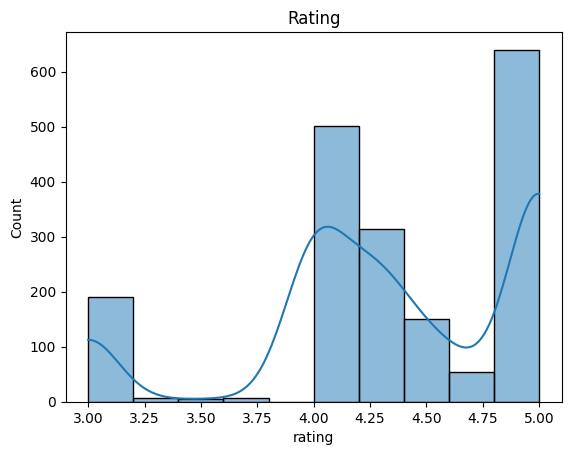

In [ ]:
# Create a histogram with a KDE plot for the 'rating' column
sns.histplot(df['rating'], bins=10,kde=True);
# Set the title of the plot
plt.title("Rating")
# Display the plot
plt.show()

* Less number of order are rated between 3 to 4
* Order that are rated between 4 to 5 are very high when compared to other orders

In [ ]:
#Check the list of Nan rating in dataframe
df['rating'].isnull().sum()

np.int64(30)

#### Observations:

* There are 30 restaurants that don’t have any ratings for any of their cuisines.

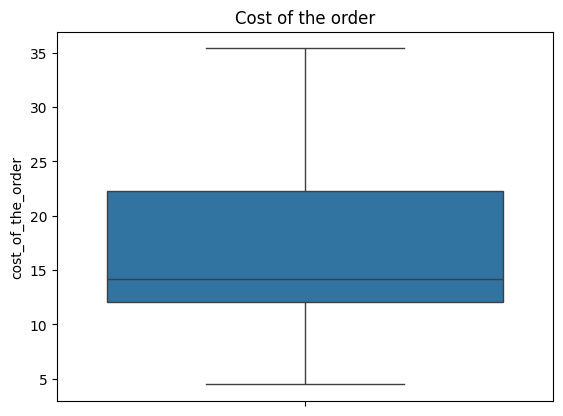

In [ ]:
# Create a box plot for the 'cost_of_the_order' column
sns.boxplot(df['cost_of_the_order']);
# Set the title of the plot
plt.title("Cost of the order")
# Display the plot
plt.show()

#### Observations:

* The box plot shows the distribution of the cost of orders.
* From the above box plot, cost of order is in between 5 to 35 dollars
* Majority of orders are between approximately \$12 and   \$22 (IQR)
* Maximun cost of order is 35 dollars
* Minimum cost of order is 5 dollars

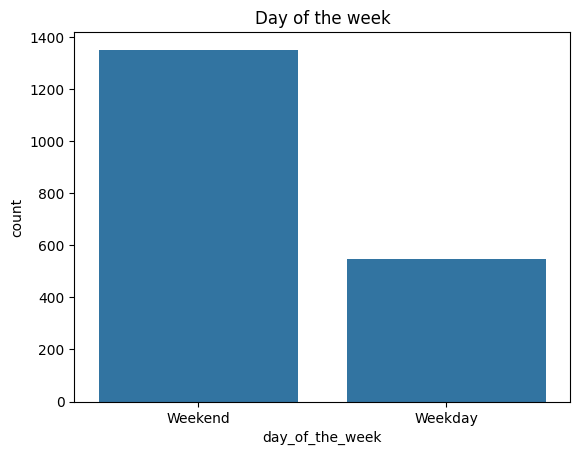

In [ ]:
# Create a count plot for the 'day_of_the_week' column
sns.countplot(x="day_of_the_week",data=df);
# Set the title of the plot
plt.title("Day of the week")
# Display the plot
plt.show()

#### Observations:

* The number of orders during weekends is more than twice that of weekdays.

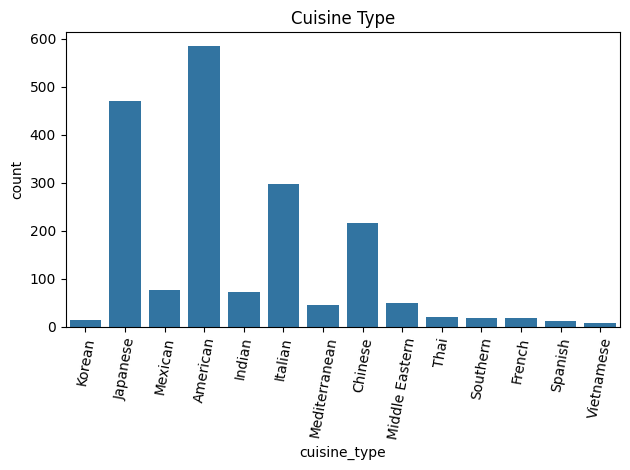

In [ ]:
# Create a count plot for the 'cuisine_type' column
sns.countplot(x="cuisine_type",data=df);
# Set the title of the plot
plt.title("Cuisine Type")
# Rotate x-axis labels for better readability
plt.xticks(rotation=80)
# Adjust layout to prevent labels overlapping
plt.tight_layout()
# Display the plot
plt.show()

#### Observations:
* There are 14 unique cuisine's.
* Top 3 and most available Cuisine's are American, Japanese and Italian
* The availability of Korean, Spanish, and Vietnamese cuisines is low compared to others

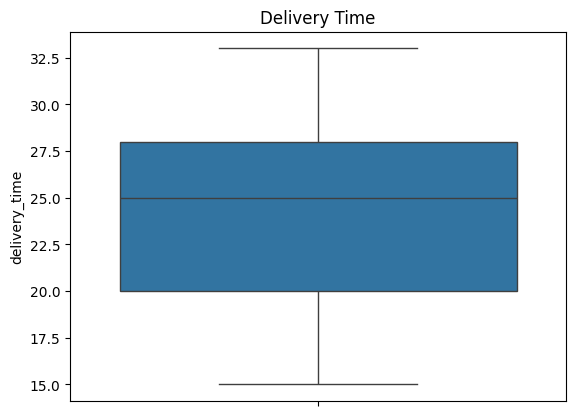

In [ ]:
# Create a box plot for the 'delivery_time' column
sns.boxplot(df["delivery_time"]);
# Set the title of the plot
plt.title("Delivery Time")
# Display the plot
plt.show()

#### Observations:

* The box plot shows the distribution of delivery times.
* The median delivery time is around 25 minutes.
* The majority of delivery happens between approximately 20 to 28 minutes
* The delivery times are almost symmetrically distributed with no outliers

In [ ]:
# Get the number of unique values in the 'restaurant_name' column
df["restaurant_name"].nunique()

178

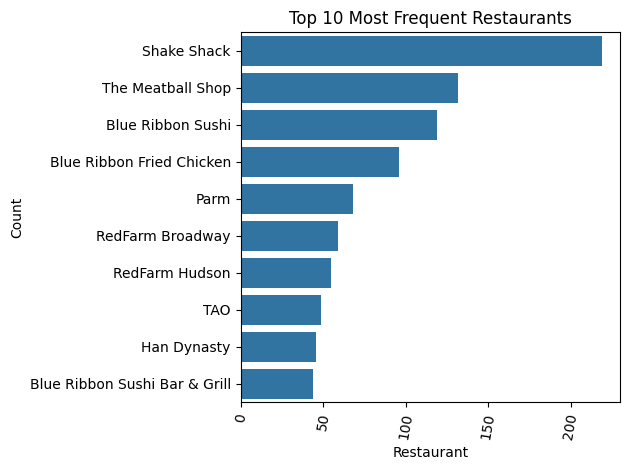

In [ ]:
# Get the top 10 most frequent restaurants
top_10 = df["restaurant_name"].value_counts().head(10)
# Create a bar plot of the top 10 restaurants
sns.barplot(x=top_10.values, y=top_10.index)
# Set the title of the plot
plt.title("Top 10 Most Frequent Restaurants")
# Set the label for the y-axis
plt.ylabel("Count")
# Set the label for the x-axis
plt.xlabel("Restaurant")
# Rotate x-axis labels for better readability
plt.xticks(rotation=80)
# Adjust layout to prevent labels overlapping
plt.tight_layout()
# Display the plot
plt.show()

#### Observations:

* The top 10 restaurants by the number of orders are:
    * Shake Shack
    * The Meatball Shop
    * Blue Ribbon Sushi
    * Blue Ribbon Fried Chicken
    * Parm
    * RedFarm Broadway
    * RedFarm Hudson
    * TAO
    * Han Dynasty
    * Blue Ribbon Sushi Bar & Grill

### **Question 7**: Which are the top 5 restaurants in terms of the number of orders received? [1 mark]

In [ ]:
# Get the top 5 most frequent restaurants and their counts
df["restaurant_name"].value_counts().head(5)

,count
restaurant_name,
Shake Shack,219
The Meatball Shop,132
Blue Ribbon Sushi,119
Blue Ribbon Fried Chicken,96
Parm,68


#### Observations:

The top 5  restaurants by the number of orders are:
* Shake Shack with 219 orders
* The Meatball Shop with 132 order
* Blue Ribbon Sushi with 119 orders
* Blue Ribbon Fried Chicken with 96 orders
* Parm with 68 orders

### **Question 8**: Which is the most popular cuisine on weekends? [1 mark]

In [ ]:
# Create a boolean filter for weekend orders
is_weekend_filter = df["day_of_the_week"]=="Weekend"
# Filter for weekend orders and get the counts of each cuisine type
weekend_popular_cusines = df[is_weekend_filter]["cuisine_type"].value_counts()
# Get the top 1 most popular cuisine on weekends
weekend_popular_cusines.head(1)

,count
cuisine_type,
American,415


#### Observations:

* Most popular cuisine on weekends is American

### **Question 9**: What percentage of the orders cost more than 20 dollars? [2 marks]

In [ ]:
# Create a boolean filter for orders with cost > 20
cost_filter = df["cost_of_the_order"]>20
# Get the number of orders with cost > 20
orders = df[cost_filter].shape[0]
# Get the total number of orders
total_orders = df.shape[0]
# Calculate the percentage of orders with cost > 20 and round to 2 decimal places
percentage=round((orders/total_orders )*100,2)
# Print the calculated percentage
print(percentage)

29.24


#### Observations:

* 29.24% of orders cost more than 20 dollars

### **Question 10**: What is the mean order delivery time? [1 mark]

In [ ]:
# Calculate the mean of the 'delivery_time' column
mean_delivery_time = df["delivery_time"].mean()
# Print the mean delivery time rounded to 2 decimal places
print(round(mean_delivery_time,2))

24.16


#### Observations:
* Mean delivery order time is 24.16 minutes

### **Question 11:** The company has decided to give 20% discount vouchers to the top 3 most frequent customers. Find the IDs of these customers and the number of orders they placed. [1 mark]

In [ ]:
# Get the counts of orders for each customer
top_customers= df["customer_id"].value_counts()
# Get the top 3 customers by order count
top_customers.head(3)

,count
customer_id,
52832,13
47440,10
83287,9


#### Observations:
* Top 3 customer IDs with number of orders placed are :


  * Customer with ID 52832 placed 13 orders
  * Customer with ID 47440 placed 10 orders
  * Customer with ID 83287 placed 9 orders





### Multivariate Analysis

### **Question 12**: Perform a multivariate analysis to explore relationships between the important variables in the dataset. (It is a good idea to explore relations between numerical variables as well as relations between numerical and categorical variables) [10 marks]


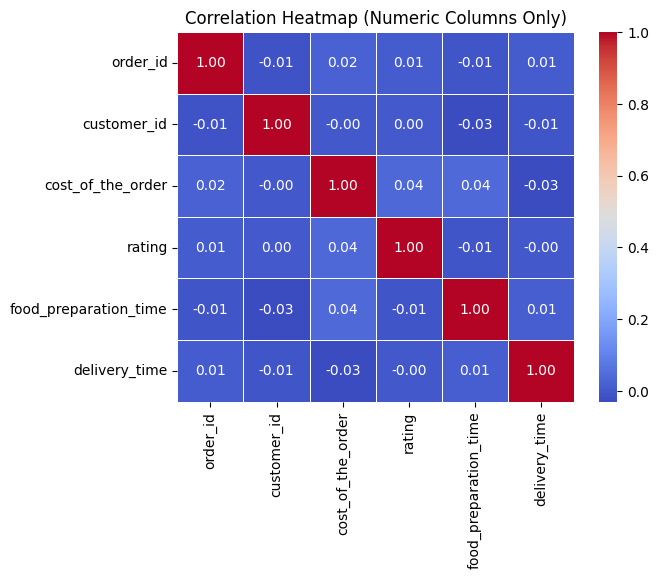

In [ ]:
# Select only numeric columns
numeric_df = df.select_dtypes(include=['number'])
# Calculate the correlation matrix
corr = numeric_df.corr()
# Create a heatmap of the correlation matrix
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
# Set the title
plt.title("Correlation Heatmap (Numeric Columns Only)")
# Display the plot
plt.show()

#### Observations on Heatmap:

* The correlation between cost_of_the_order and delivery_time is close to 0, indicating no significant linear relationship.
* The is no correlation or very weak correlation between most of the columns
* food_preparation_time and delivery_time also show a very weak positive correlation.


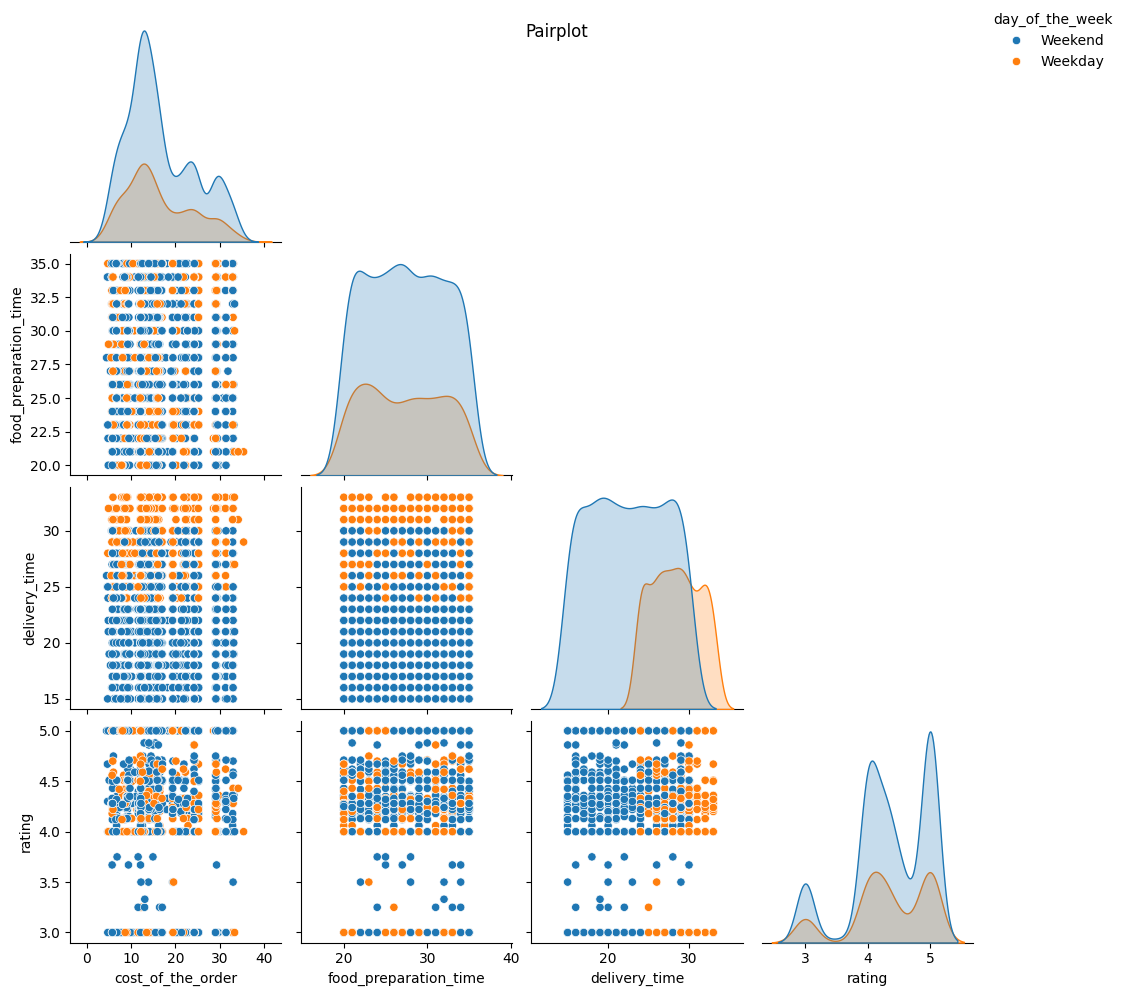

In [ ]:
# Create a pair plot for selected numerical columns, colored by day of the week
df_pair_plot = sns.pairplot(df, vars=['cost_of_the_order', 'food_preparation_time', 'delivery_time', 'rating'], hue='day_of_the_week',corner=True)
# Set the title
plt.suptitle("Pairplot")
# Position the legend
df_pair_plot._legend.set_loc('upper right')
# Display the plot
plt.show()

#### Observations:

* Delivery time is more in weekends than in weekdays
* Cost of the order is not impacting the rating or the delivery time.
* Food Preparation time is not impacting the rating or delivery time.

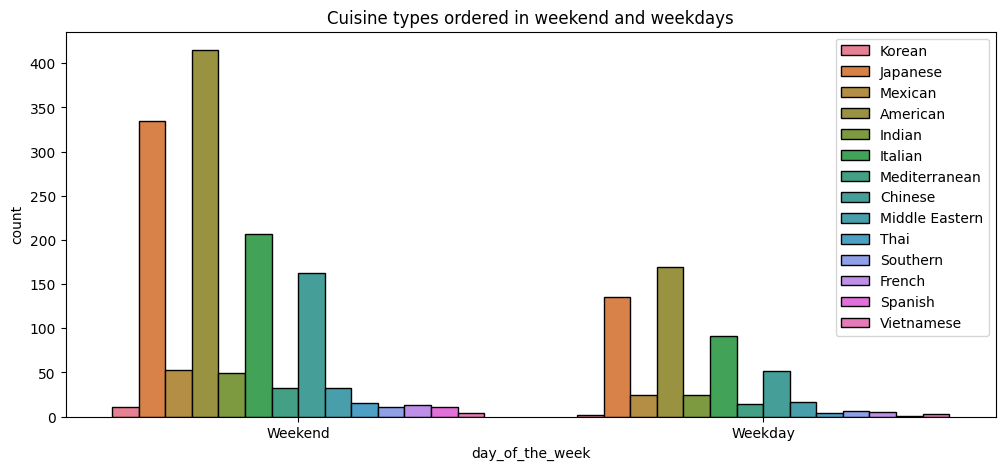

In [ ]:
# Set the figure size
plt.figure(figsize=(12, 5))
# Create a count plot of cuisine types by day of the week
sns.countplot(data=df, x='day_of_the_week', hue='cuisine_type',edgecolor="black")
# Set the title
plt.title("Cuisine types ordered in weekend and weekdays")
# Set the legend position
plt.legend(bbox_to_anchor=(1,1))
# Display the plot
plt.show()

#### Observations :

* Weekends have significantly more orders than weekdays across almost all cuisine types.
* American, Japanese, and Italian cuisines are the most frequently ordered on both weekdays and weekends.
* Demand of top cuisines is consistent in weekdays and weekends
* Vietnamese is one of the least ordered cuisine.

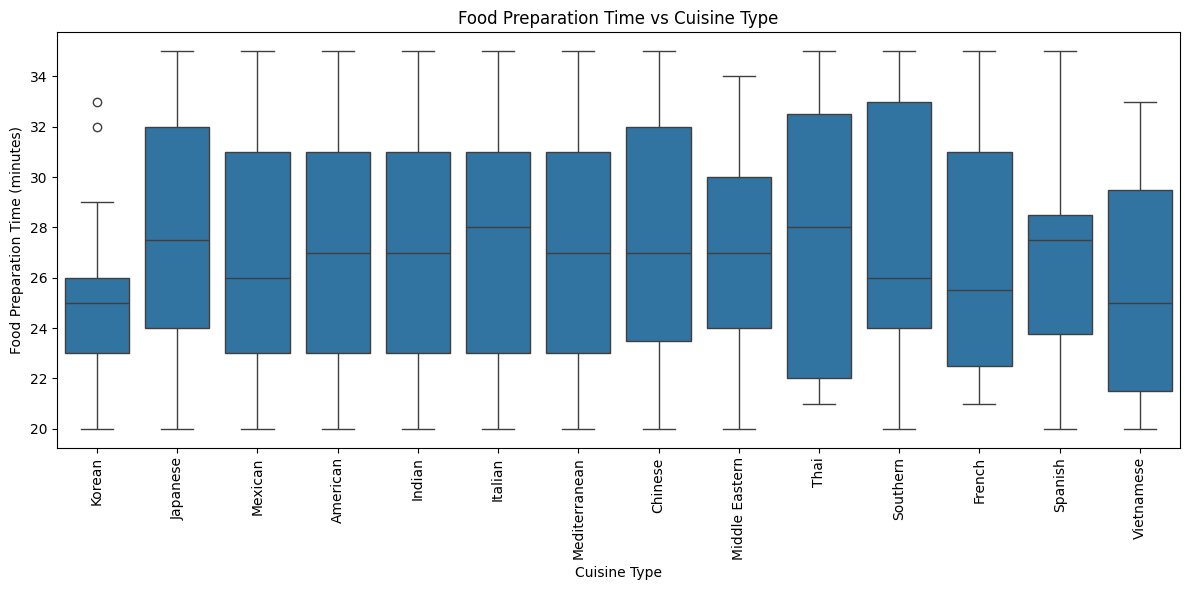

In [ ]:
# Set the figure size
plt.figure(figsize=(12, 6))
# Create a box plot of food preparation time by cuisine type
sns.boxplot(x='cuisine_type', y='food_preparation_time', data=df)
# Set the title
plt.title('Food Preparation Time vs Cuisine Type')
# Set the label for the x-axis
plt.xlabel('Cuisine Type')
# Set the label for the y-axis
plt.ylabel('Food Preparation Time (minutes)')
# Rotate x-axis labels
plt.xticks(rotation=90)
# Adjust the layout
plt.tight_layout()
# Display the plot
plt.show()

### Observations
* The box plot shows the distribution of food preparation times across different cuisine types.
* The median food preparation time for most cuisine types is around 25-30 minutes.
* Cuisine type like Thai has a wider range of preparation time.
* There are some outliers in preparation times for certain cuisines like Korean cusine which can have longer preparation time



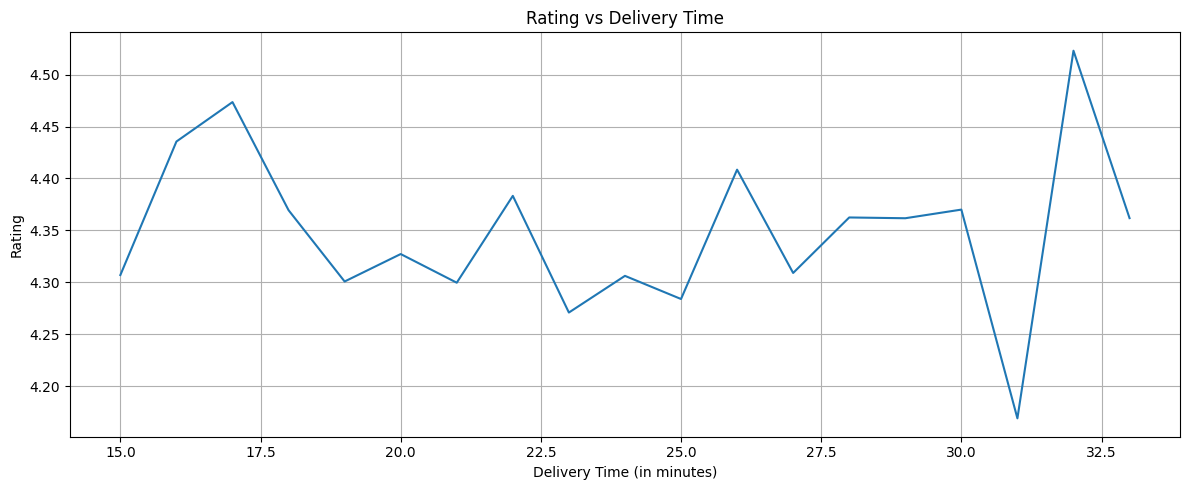

In [ ]:
# Set the figure size
plt.figure(figsize=(12, 5))
# Create a line plot of rating vs delivery time
sns.lineplot(y='rating', x='delivery_time', data=df, errorbar=None)
# Set the title of the plot
plt.title('Rating vs Delivery Time')
# Set the label for the x-axis
plt.xlabel('Delivery Time (in minutes)')
# Set the label for the y-axis
plt.ylabel('Rating')
# Add a grid to the plot
plt.grid(True)
# Adjust layout
plt.tight_layout()
# Display the plot
plt.show()

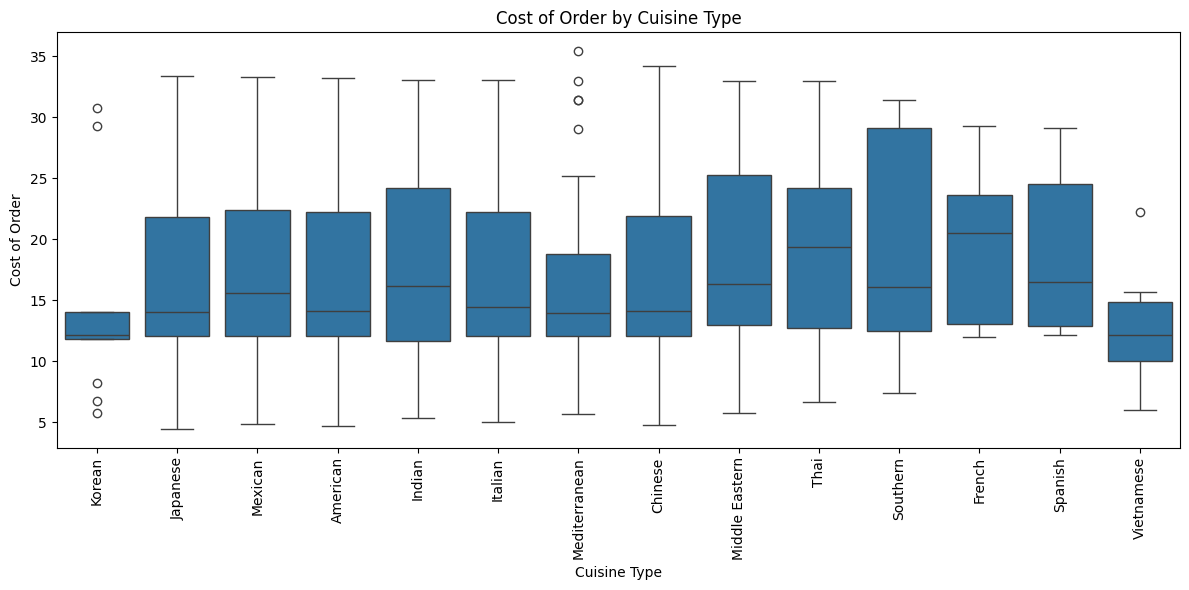

In [ ]:
# Set the figure size
plt.figure(figsize=(12, 6))
# Create a box plot of cost of order by cuisine type
sns.boxplot(x='cuisine_type', y='cost_of_the_order', data=df)
# Set the title
plt.title('Cost of Order by Cuisine Type')
# Set the label for the x-axis
plt.xlabel('Cuisine Type')
# Set the label for the y-axis
plt.ylabel('Cost of Order')
# Rotate x-axis labels for better readability
plt.xticks(rotation=90)
# Adjust layout
plt.tight_layout()
# Display the plot
plt.show()

### Observations

* Vietnamese and Korean cuisines has lowest median order cost.
* Cost of some items in Korean  cusinie can be very low because of outliers in Q1
* Cost of some items in Korean and Mediterranean can be more expensive as there are multiple outliers below the box

### **Question 13:** The company wants to provide a promotional offer in the advertisement of the restaurants. The condition to get the offer is that the restaurants must have a rating count of more than 50 and the average rating should be greater than 4. Find the restaurants fulfilling the criteria to get the promotional offer. [3 marks]

In [ ]:
# Group the DataFrame by 'restaurant_name' and calculate the count of ratings for each restaurant.
df_rating_count=df.groupby("restaurant_name")["rating"].transform("count")
# Group the DataFrame by 'restaurant_name' and calculate the mean of the ratings for each restaurant.
df_rating_mean=df.groupby("restaurant_name")["rating"].transform("mean")
# Filter the DataFrame to include only rows where the rating count > 50 and the mean rating > 4.
df_rating_mean_filer = df[(df_rating_count > 50 ) & (df_rating_mean> 4)]
# Get the unique restaurant
df_rating_mean_filer["restaurant_name"].unique()

array(['Blue Ribbon Fried Chicken', 'The Meatball Shop', 'Shake Shack',
       'RedFarm Hudson', 'Blue Ribbon Sushi', 'Parm', 'RedFarm Broadway'],
      dtype=object)

#### Observations:

The restaurants that fulfill the criteria to get the promotional offer are:
* Blue Ribbon Fried Chicken
* The Meatball Shop
* Shake Shack
* RedFarm Hudson
* Blue Ribbon Sushi
* Parm
* RedFarm Broadway

### **Question 14:** The company charges the restaurant 25% on the orders having cost greater than 20 dollars and 15% on the orders having cost greater than 5 dollars. Find the net revenue generated by the company across all orders. [3 marks]

In [ ]:
# Define a function to calculate revenue based on order cost
def total_revenue(cost):
  if(cost > 20):
    return cost * 0.25
  elif(cost > 5):
    return cost * 0.15
  else:
    return 0

In [ ]:
# Apply the total_revenue function to the 'cost_of_the_order' column and sum the revenue
df_revenue = df["cost_of_the_order"].apply(total_revenue);
print(round(df_revenue.sum(),2))

6166.3


#### Observations:
* Net revenue generated by company is 6166.3 dollars

### **Question 15:** The company wants to analyze the total time required to deliver the food. What percentage of orders take more than 60 minutes to get delivered from the time the order is placed? (The food has to be prepared and then delivered.) [2 marks]

In [ ]:
# Calculate the total order time and filter for orders taking more than 60 minutes
df_total_order_time= df["delivery_time"] + df["food_preparation_time"]
orders_60_min = df[df_total_order_time > 60]
# Calculate and print the percentage of orders taking more than 60 minutes
order_60_percentage = (orders_60_min.shape[0]/df.shape[0]) * 100
print(round(order_60_percentage,2))

10.54


#### Observations:
Percentage of orders that take more than 60 minutes is 10.54%

### **Question 16:** The company wants to analyze the delivery time of the orders on weekdays and weekends. How does the mean delivery time vary during weekdays and weekends? [2 marks]

In [ ]:
# Calculate and print the mean delivery time grouped by day of the week
delivery_mean_time=df.groupby("day_of_the_week")["delivery_time"].mean()
print(delivery_mean_time)

day_of_the_week
Weekday    28.340037
Weekend    22.470022
Name: delivery_time, dtype: float64


#### Observations:
* Mean delivery time on weekday is 28.34 minutes
* Mean delivery time on weekend is 22.47 minutes
* Mean delivery time on weekdays is approximatetly 5.87 minutes more than weekends.

### Conclusion and Recommendations

### **Question 17:** What are your conclusions from the analysis? What recommendations would you like to share to help improve the business? (You can use cuisine type and feedback ratings to drive your business recommendations.) [6 marks]

### Conclusions:

* The majority of orders are placed during weekends, indicating higher demand at the end of the week.
* American, Japanese, and Italian cuisines emerge as the most preferred choices among customers.
* A notable proportion of orders remain unrated, suggesting an opportunity to improve feedback collection.
* A significant share of orders exceed a value of $20.
* The top three most frequent customers have been successfully identified.
* Average delivery times are observed to be longer on weekdays than on weekends.
* Restaurants qualifying for the promotional offer—based on rating volume and average rating—have been determined.
* The company’s net revenue has been accurately calculated.
* Only a small fraction of orders take more than 60 minutes to be delivered.

### Recommendations:

**Get More Customer Feedback**: Make it easy to rate and offer small rewards to increase reviews. Use feedback to find areas for improvement.

**Improve Weekend Operations**: Add more staff on weekends to handle extra orders faster and keep customers happy.

**Promote Popular Cuisines**: Focus on American, Japanese, and Italian dishes. Study high-value orders to plan better offers.

**Speed Up Weekday Deliveries**: Find out why weekday deliveries take longer and fix issues like traffic delays or low staff.

**Fix Long Delivery Times**: Check delayed orders and solve problems causing waits over 60 minutes.

**Loyalty Program**: Increase customers rewards or discounts to encourage repeat orders.

**Work With Top Restaurants**: Partner with highly rated restaurants for joint promotions that attract more customers.

